In [1]:
import jax
import numpy as np
import matplotlib.pyplot as plt

import os
import sys

import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d

from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm, logm


sys.path.append("../")

%load_ext autoreload
%autoreload 2
import pulse_simulator as ps

/home/andy/Documents/Research/Projects/pulse-simulator/pulse-simulator/.venv/lib/python3.12/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [2]:
from tqdm import tqdm

In [4]:
# Config stuff
jax.config.update("jax_enable_x64", True)

# Set JAX_PLATFORMS=true
os.environ["JAX_PLATFORM_NAME"] = "cpu"

# Set the memory fraction
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"]="0.49"

qk_d.array.Array.set_default_backend("jax")

# Check if GPU is available
jax.default_backend()

'cpu'

# ZZ crosstalk from device data

In [37]:
data = np.loadtxt(
    "../playground/fit_data.csv", 
    delimiter=",",
    skiprows=1
)

In [ ]:
x, y = data.T
x = x * 0.5e-9

# Take the Fourier transform of the data
fft_data = np.fft.fftshift(np.fft.fft(y))
fft_freqs = np.fft.fftshift(np.fft.fftfreq(len(y), d=(x[1] - x[0])))

# Plot the spectrum
plt.figure(figsize=(10, 6))
plt.plot(fft_freqs, np.abs(fft_data), marker='o')
plt.xlabel('Frequency')
plt.ylabel('Amplitude')
plt.title('Fourier Transform Spectrum')
plt.grid(True)
plt.show()


In [ ]:
fft_freqs[np.argsort(np.abs(fft_data))[-5:]]

In [ ]:
127930 / 2 / np.pi / 1e3

The crosstalk is around 20 kHz.

In [ ]:
# From above fit from XY4 experiment
zz = 127930 / 1e9

# From Brisbane data
delta = 2 * np.pi * 0.11
alpha = -2 * np.pi * 0.31

J = np.sqrt(zz * (delta**2 - alpha**2) / 2 / alpha)
J / 2 / np.pi * 1e3 # MHz

# Simulate ECR (w/ or w/o Rotary)

In [9]:
num_qubits = 10

coupling_map = (
    [[i, i + 1] for i in range(num_qubits - 1)] 
    + [[i + 1, i] for i in range(num_qubits - 1)]
)

backend = qk_fp.GenericBackendV2(
    num_qubits=num_qubits,
    basis_gates=["id", "rz", "sx", "x", "ecr"],
    coupling_map=coupling_map,
    seed=17,
)

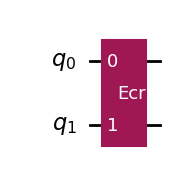

In [10]:
circ = qk.QuantumCircuit(2)
circ.ecr(0, 1)
circ.draw("mpl")

In [11]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

dt = 0.5 # backend.configuration().dt * ns
desired_1qb_duration = 120  # dt
desired_2qb_duration = 120 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

# Gates
names_1qb = ["X1", "X2", "SX1", "SX2", "ID1", "ID2"]
cal_1qb_default = ps.default_single_qubit_gateset(names_1qb, duration_1qb, dt)


In [149]:
sweep_angles = np.linspace(0, 2 * np.pi, 10)
fidelities = []

for θ in tqdm(sweep_angles):

    model_name = "SWPT"
    # model_name = "Toy"

    # ECR gate
    angle = ps.two_qubit_models.calibrate_default_cross_resonance_drive(model_name)
    cal_2qb_default = ps.default_gateset({"+": angle, "-": -angle}, duration_2qb, dt)

    # Rotary -- does not have J dependence
    rotary_2qb = ps.default_gateset({"+": θ, "-": -θ}, duration_2qb, dt)

    # Build the pulse simulator
    registers = [0, 1]
    simulator = ps.Simulator(registers, backend)

    # Add some errors to make it interesting!
    res = simulator.simulate_circuit(
        circ,
        cal_1qb_default,
        cal_2qb_default,
        dt,
        include_crosstalk=True,
        include_dissipation=False,
        cross_resonance_model_name=model_name,
        rotary_gates=rotary_2qb,
        gpu=True,
    )

    # Let's check in on the simulation after each gate
    moments = simulator.get_moments()
    measure_times = (
        np.cumsum(ps.durations_of_moments(moments, duration_1qb, duration_2qb)) * backend.dt
    )

    # These were the expected outcomes
    U_goals = []
    for i in range(len(moments)):
        U_goals.append(ps.build_operator(moments[0 : i + 1], registers))

    # How did we do?
    fid = np.array(
        [qk.quantum_info.process_fidelity(R, U) for R, U in zip(res[1:], U_goals)]
    )

    fidelities.append(fid)

100%|██████████| 10/10 [01:39<00:00,  9.97s/it]


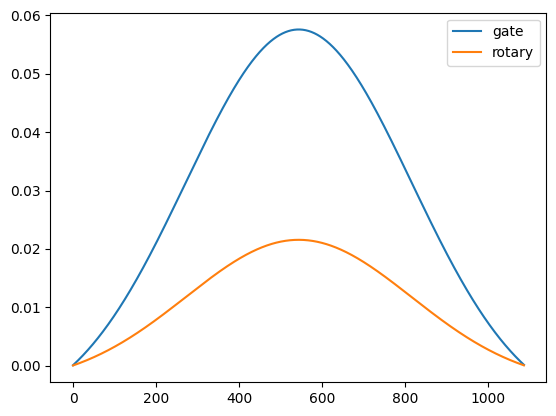

In [168]:
plt.plot(ps.get_samples(cal_2qb_default["+"]).real, label="gate")
plt.plot(ps.get_samples(rotary_2qb["+"]).real, label="rotary")
plt.legend()

In [150]:
# simulator.get_schedules()[0].draw()

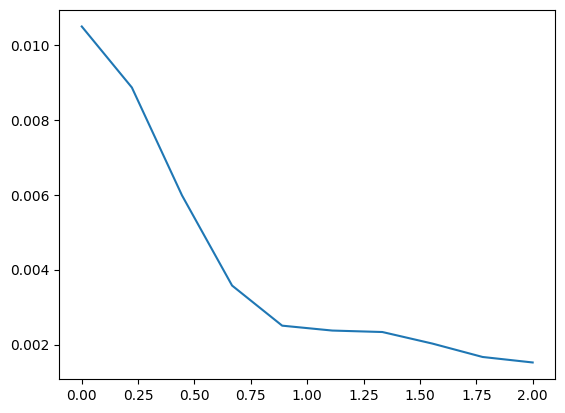

In [152]:
fig, ax = plt.subplots()
ax.plot(
    sweep_angles / np.pi,
    1 - np.array(fidelities),
)

# ECR gate checks

ECR:$$ \frac{1}{\sqrt{2}} \left( XI - YX \right) $$
(flip order if Qiskit)

In [61]:
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
I = np.identity(2)

# ECR = 1/np.sqrt(2) * (np.kron(X, I) - np.kron(Y, X))

# Qiskit
ECR1 = 1/np.sqrt(2) * (np.kron(I, X) - np.kron(X, Y))
ECR2 = expm(1j * np.pi / 8 * np.kron(X, Z)) @ np.kron(I, X) @ expm(-1j * np.pi / 8 * np.kron(X, Z))

# Check the fidelity
print(qk.quantum_info.process_fidelity(res[-1], qk.quantum_info.Operator(ECR1)))
print(qk.quantum_info.process_fidelity(res[-1], qk.quantum_info.Operator(ECR2)))

0.9976224190383107
0.997622419038311


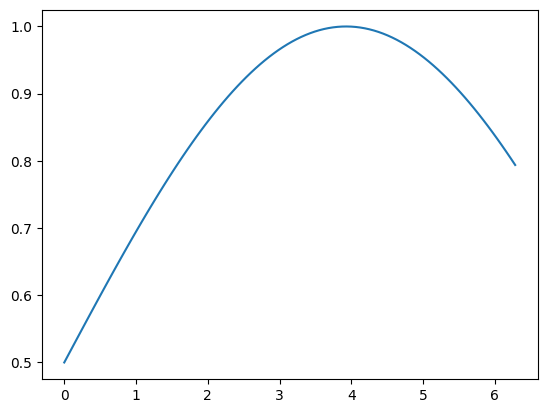

In [62]:
def test_gate(x):
    # H_drive = np.kron(I, X) + 1/10 * np.kron(X, Z)
    H_drive = -np.kron(X, I) + 1/10 * np.kron(X, Z)
    # H_drive = np.kron(X, Z)
    return qk.quantum_info.Operator(
        expm(1j * x * H_drive) @ np.kron(I, X) @ expm(-1j * x * H_drive)
    )

xs = np.linspace(0, 2 * np.pi, 100)
plt.plot(xs, [
    qk.quantum_info.process_fidelity(test_gate(x), qk.quantum_info.Operator(ECR2))
    for x in xs
])

# Rotary checks

In [5]:
sampler = ps.BackendSampler(1e9)

In [6]:
α = sampler.frequency_units(sampler.draw_anharmonicity(mean=True), angular=True)
J = sampler.frequency_units(sampler.draw_coupling(mean=True), angular=True)
Δ = sampler.frequency_units(sampler.draw_frequency(std=True), angular=True)

In [9]:
c_ZZ = 2 * α * J**2 / (Δ**2 - α**2)
c_XI = -J / (Δ + α)
c_XZ = J / (Δ + α) * α / Δ

In [10]:
# -1 / (Δ + α), 1 / (Δ + α) * α / Δ
c_XI, c_XZ

(0.0083, 0.023390909090909087)

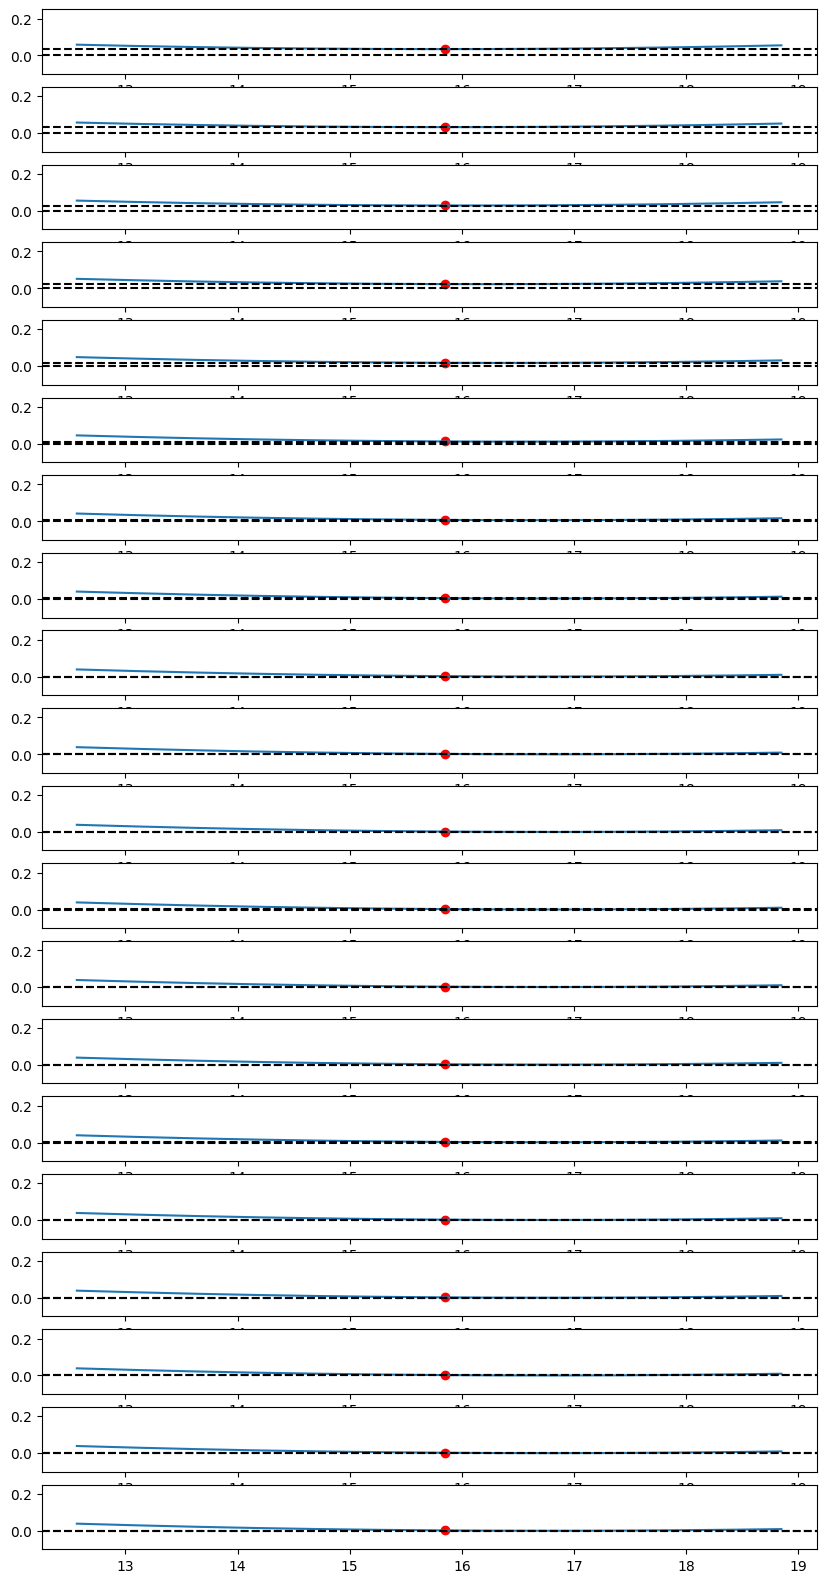

In [181]:
def test_gate(x, y):
    H0 = 50 * c_ZZ * np.kron(Z, Z)
    H_drive = c_XZ * np.kron(X, Z) + c_XI * np.kron(X, I)
    H1 = H0 + H_drive
    return qk.quantum_info.Operator(
        expm(1j * x * H1 + 1j * y * np.kron(X, I))
        @ np.kron(I, X)
        @ expm(-1j * x * H1 - 1j * y * np.kron(X, I))
    )


sweep_angles2 = np.linspace(0.0, 2 * np.pi, 20)
infidelities2 = []

fig, axes = plt.subplots(len(sweep_angles2), 1, figsize=(10, 20))

for i, y in enumerate(sweep_angles2):
    ax = axes.flatten()[i]
    xs = np.linspace(4 * np.pi, 6 * np.pi, 250)
    ys = [
        1
        - qk.quantum_info.process_fidelity(
            test_gate(x, y), qk.quantum_info.Operator(ECR2)
        )
        for x in xs
    ]
    if i == 0:
        argmin = np.argmin(ys)
    infidelities2.append(ys[argmin])

    ax.plot(xs, ys)
    ax.scatter(xs[argmin], ys[argmin], color="red")
    ax.axhline(min(ys), color="black", linestyle="--")
    ax.axhline(0, color="black", linestyle="--")
    ax.set_ylim([-0.1, 0.25])

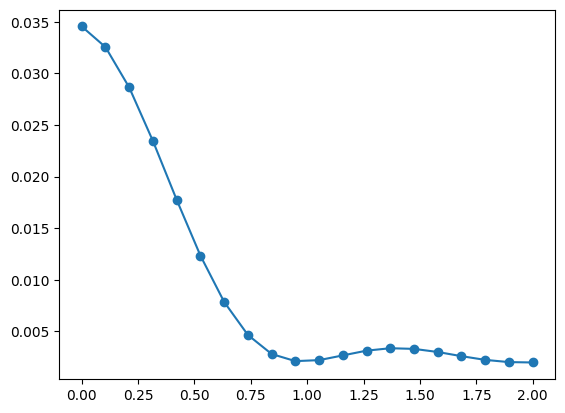

In [183]:
fig, ax = plt.subplots()
ax.plot(sweep_angles2 / np.pi, infidelities2, marker='o')